# 12 图像超分辨率：低清矩阵 → 插值 → 学习残差 → 高清预测

默认用 sklearn 自带的手写数字，在独立测试集上比较双三次插值与小型 CNN。
8×8 图像先降采样到 4×4，再重建到 8×8。这是尺寸很小的教学实验，不是修复真实照片细节的保证。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder))
        break
else:
    raise FileNotFoundError("请从完整项目的根目录或 notebooks 目录运行。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import torch
from torch import nn
import torch.nn.functional as F
dev = device()
torch.set_num_threads(2)
print("计算设备:", dev)


计算设备: cpu


## 1. 构造可解释的低清—高清配对

只按训练集训练，保留集只评价。降采样用面积插值；基线使用双三次插值。

数值怎么读：一张低清图片是 4×4 矩阵，插值与目标各是 8×8 矩阵。批量输入 CNN 时增加通道维，变成 `[N,1,8,8]`。例如输出矩阵中 0.9 表示接近白色、0.1 表示接近黑色；范围为 [0,1]，不是原始数字数据的 0～16。插值只增加采样位置，学习残差才利用训练数据修正局部结构。


低清输入 4×4:
 [[0.   0.42 0.31 0.  ]
 [0.   0.75 0.22 0.02]
 [0.   0.81 0.28 0.31]
 [0.   0.44 0.52 0.36]]
高清目标前 4×4:
 [[0.   0.   0.   0.44]
 [0.   0.   0.25 1.  ]
 [0.   0.   0.75 0.69]
 [0.   0.   0.94 0.62]]


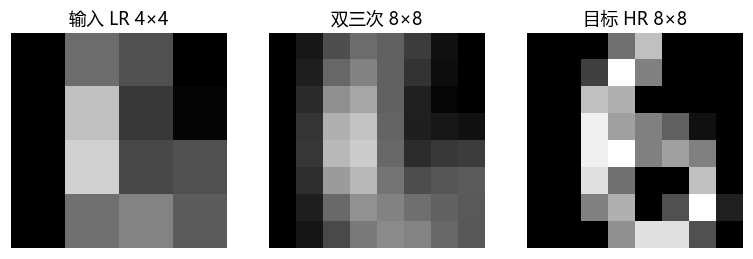

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/12_sr_inputs.png')

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
images = load_digits().images.astype(np.float32)/16.
train, test = train_test_split(images, test_size=.2, random_state=42)
def degrade_and_resize(images):
    lr = np.stack([cv2.resize(im, (4, 4), interpolation=cv2.INTER_AREA) for im in images])
    up = np.stack([cv2.resize(im, (8, 8), interpolation=cv2.INTER_CUBIC) for im in lr])
    return lr, up
train_lr, train_up = degrade_and_resize(train)
test_lr, test_up = degrade_and_resize(test)
print("低清输入 4×4:\n", np.round(test_lr[0], 2))
print("高清目标前 4×4:\n", np.round(test[0, :4, :4], 2))
fig, axs = plt.subplots(1, 3, figsize=(9, 3))
for ax, im, title in zip(axs, [test_lr[0], test_up[0], test[0]], ["输入 LR 4×4", "双三次 8×8", "目标 HR 8×8"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")
save_figure("12_sr_inputs")


## 2. 残差学习

$\hat I_{HR}=I_{bicubic}+f_\theta(I_{bicubic})$。CNN 只预测修正量。
输出层零初始化，使模型开始时等价于插值基线，避免比较一个故意很差的随机基线。


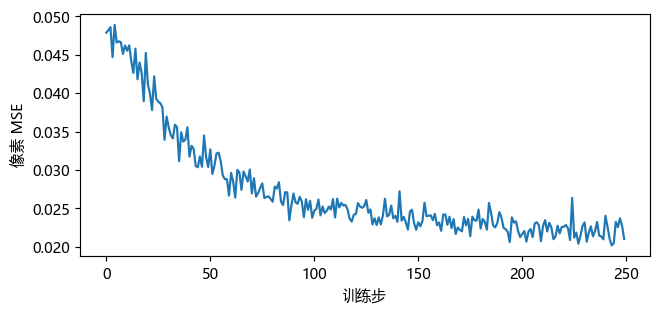

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/12_sr_loss.png')

In [3]:
class ResidualSR(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 24, 3, padding=1), nn.ReLU(),
                                 nn.Conv2d(24, 24, 3, padding=1), nn.ReLU(), nn.Conv2d(24, 1, 3, padding=1))
        nn.init.zeros_(self.net[-1].weight); nn.init.zeros_(self.net[-1].bias)
    def forward(self, x): return x+self.net(x)

model = ResidualSR().to(dev)
optimizer = torch.optim.Adam(model.parameters(), lr=.002)
X = torch.from_numpy(train_up[:, None]).to(dev)
Y = torch.from_numpy(train[:, None]).to(dev)
losses = []
for step in range(250):
    ids = torch.randint(len(X), (64,), device=dev)
    loss = F.mse_loss(model(X[ids]), Y[ids])
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    losses.append(loss.item())
plt.figure(figsize=(7, 3)); plt.plot(losses); plt.xlabel("训练步"); plt.ylabel("像素 MSE")
save_figure("12_sr_loss")


## 3. 评价：同一保留集上的 MSE 与 PSNR

图像范围为 [0,1]，$PSNR=10\log_{10}(1/MSE)$。按每张图先算 PSNR 再取均值。
只看视觉图容易选到有利的样本，因此同时报告整个测试集。


双三次 PSNR=13.35 dB
残差CNN PSNR=16.83 dB
输出超分矩阵前 4×4:
 [[0.02 0.09 0.04 0.57]
 [0.   0.05 0.21 0.89]
 [0.   0.02 0.45 0.88]
 [0.   0.02 0.64 0.95]]


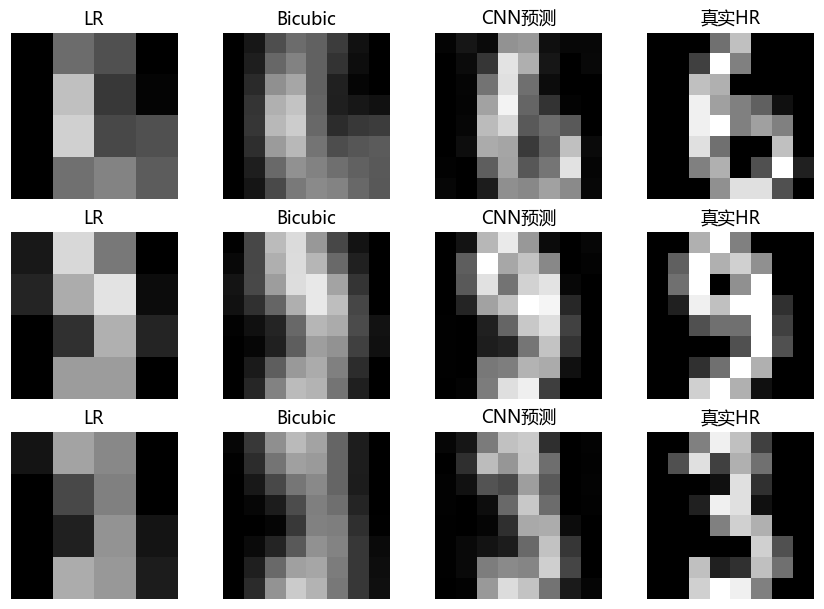

In [4]:
model.eval()
with torch.no_grad():
    sr = model(torch.from_numpy(test_up[:, None]).to(dev)).clamp(0, 1).cpu().numpy()[:, 0]
def mean_psnr(prediction, target):
    mse = np.mean((prediction-target)**2, axis=(1, 2))
    return np.mean(10*np.log10(1/np.maximum(mse, 1e-12)))
print(f"双三次 PSNR={mean_psnr(test_up.clip(0,1),test):.2f} dB")
print(f"残差CNN PSNR={mean_psnr(sr,test):.2f} dB")
print("输出超分矩阵前 4×4:\n", np.round(sr[0, :4, :4], 2))
fig, axs = plt.subplots(3, 4, figsize=(10, 7))
for row in range(3):
    for ax, im, title in zip(axs[row], [test_lr[row], test_up[row], sr[row], test[row]], ["LR", "Bicubic", "CNN预测", "真实HR"]):
        ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")
save_figure("12_sr_outputs")
assert sr.shape == test.shape and np.isfinite(sr).all()


## 4. 真实照片域外实验

只在数字上训练的模型，不一定能提升水果照片。下图使用同一低清图比较插值与 CNN，并保留原图作为参考。
这种域外实验可以揭示训练分布限制，不应把“像素数变多”写成“真实细节恢复”。


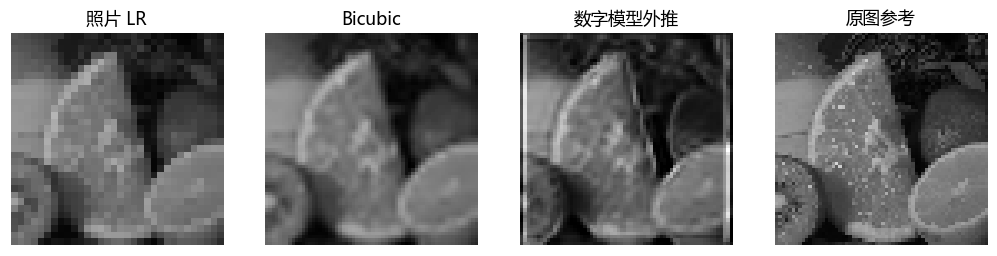

In [5]:
photo_path = ROOT / "assets/photos/fruits.jpg"
if photo_path.exists():
    photo = cv2.imread(str(photo_path), cv2.IMREAD_GRAYSCALE)
    photo = cv2.resize(photo, (64, 64)).astype(np.float32)/255.
    lr = cv2.resize(photo, (32, 32), interpolation=cv2.INTER_AREA)
    bicubic = cv2.resize(lr, (64, 64), interpolation=cv2.INTER_CUBIC)
    with torch.no_grad():
        output = model(torch.from_numpy(bicubic[None, None]).to(dev)).clamp(0, 1).cpu().numpy()[0, 0]
    fig, axs = plt.subplots(1, 4, figsize=(12, 3))
    for ax, im, title in zip(axs, [lr, bicubic, output, photo], ["照片 LR", "Bicubic", "数字模型外推", "原图参考"]):
        ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(title); ax.axis("off")
    save_figure("12_sr_photo_domain_shift")
else:
    print("请先运行项目素材准备步骤，再尝试真实照片域外实验。")


## 5. 学生练习

1. 改成 2×2 → 8×8，比较信息损失。
2. 在同一测试集上检查每张图的 PSNR，找出最差的 5 张。
3. 将 MSE 改为 L1，解释训练目标与视觉效果的关系。

来源：[SRCNN 原论文](https://arxiv.org/abs/1501.00092)、[EDSR 残差超分辨率](https://arxiv.org/abs/1707.02921)。本课是简化的残差 CNN，并非完整 SRCNN/EDSR 复现。
